# Bayesian inference: toy examples

Companion notebook to the lecture *Bayesian Inference in Cosmology*. Same model, mock data and seed as `make_figs.py`:

$cz = a + H_0\,d + \epsilon$, $\sigma = 300$ km/s, $N = 30$ galaxies, $d \in [20, 400]$ Mpc, truth $H_0 = 70$, $a = 0$.

Run top to bottom. Needs numpy, scipy, matplotlib. ipywidgets is optional (section 7).

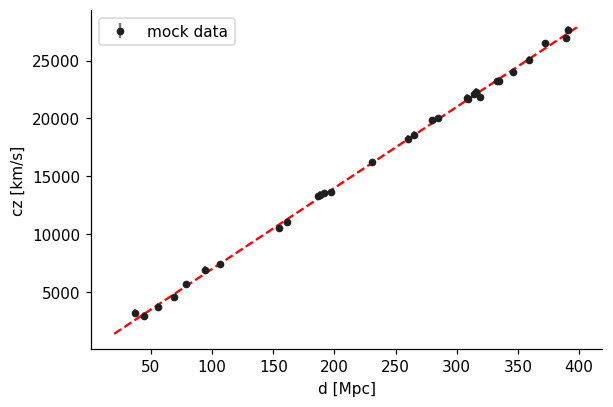

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import chi2 as chi2dist

C_DATA, C_POST, C_LIK, C_GREY = '#1f1f1f', '#1b5e8c', '#c62828', '#777777'
trapezoid = getattr(np, 'trapezoid', None) or np.trapz   # numpy 2 renamed trapz
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

rng = np.random.default_rng(42)      # same seed and draws as make_figs.py and the slides
H0_TRUE, A_TRUE, SIG, N = 70.0, 0.0, 300.0, 30
d = np.sort(rng.uniform(20, 400, N))              # Mpc
v = A_TRUE + H0_TRUE * d + rng.normal(0, SIG, N)  # km/s

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(d, v, yerr=SIG, fmt='o', ms=4, color=C_DATA, ecolor=C_GREY, label='mock data')
ax.plot([20, 400], [H0_TRUE*20, H0_TRUE*400], 'r--')  # plot the line of the true value
ax.set_xlabel('d [Mpc]'); ax.set_ylabel('cz [km/s]'); ax.legend(); plt.show()

## 1. Sequential updating

We infer the Hubble constant $H_0$ from galaxy distances $d_i$ (Mpc) and velocities $v_i$ (km/s). In this section the intercept $a$ is **fixed at zero**:

$$v_i = H_0 d_i + \epsilon_i, \qquad \epsilon_i \sim \mathcal N(0,\mathrm{SIG}^2).$$

The velocity errors are independent, `SIG = 300` km/s is known, and distances are treated as exact. These assumptions give the likelihood

$$p(\mathbf v\mid H_0,\mathbf d) \propto
\exp\!\left[-\frac{1}{2\mathrm{SIG}^2}\sum_i(v_i-H_0d_i)^2\right].$$

Here `mu0` is our prior mean for $H_0$, and `s0` is its **standard deviation**, both in km/s/Mpc. In the usual mean/variance notation, the prior is $H_0\sim\mathcal N(\mu_0,s_0^2)$. We compare means 55 and 85 with the same standard deviation 12.

### Where the update equations come from

Bayes' rule multiplies the Gaussian prior by the likelihood. Expanding the squared terms and retaining terms that depend on $H_0$ gives

$$\log p(H_0\mid\mathbf d,\mathbf v)
= -\frac12\left[
\underbrace{\left(\frac{1}{s_0^2}+\frac{\sum_i d_i^2}{\mathrm{SIG}^2}\right)}_{P}
H_0^2
-2\underbrace{\left(\frac{\mu_0}{s_0^2}+\frac{\sum_i d_iv_i}{\mathrm{SIG}^2}\right)}_{Q}H_0
\right]+\text{constant}.$$

Completing the square produces another Gaussian:

$$p(H_0\mid\mathbf d,\mathbf v)=\mathcal N(\mu,s^2),
\qquad \mu=\frac{Q}{P},\qquad s=\frac{1}{\sqrt P}.$$

**Precision** is inverse variance: $P=1/s^2$. The prior contributes $1/s_0^2$ and a galaxy contributes $d_i^2/\mathrm{SIG}^2$. For a nonzero distance, that galaxy alone estimates $H_0$ as $v_i/d_i$ with standard deviation $\mathrm{SIG}/|d_i|$; its contribution to $Q$ is its estimate multiplied by its precision. Thus the posterior mean is a precision-weighted average of the prior mean and the individual estimates. At fixed velocity noise, distant galaxies carry more information about the slope.

### Why sequential and joint updates agree

After each galaxy, use the posterior mean and standard deviation as the next prior. Each step adds $d_i^2/\mathrm{SIG}^2$ to $P$ and $d_iv_i/\mathrm{SIG}^2$ to $Q$. Addition gives the same totals whether we process the independent galaxies one at a time, in any order, or together. The final answers should agree up to floating-point rounding.

The data here are sorted by distance, so nearby galaxies arrive first. This affects the intermediate path, but not the final posterior. Every independent observation is used once; reusing a galaxy would incorrectly count its information twice.

In [2]:
def update(mu0, s0, dsub, vsub):
    """Update a Gaussian prior for H0 using a batch of independent galaxies.

    Model: v = H0 * d + Gaussian noise with known standard deviation SIG.
    The intercept is fixed at zero and distance errors are ignored.

    Parameters
    ----------
    mu0, s0 : float
        Prior mean and standard deviation of H0 [km/s/Mpc].
        s0 is a standard deviation, not a variance.
    dsub, vsub : array-like
        Matching distances [Mpc] and velocities [km/s] for new galaxies.
        A batch can contain one galaxy or the entire sample.

    Returns
    -------
    mu, s : float
        Posterior mean and standard deviation [km/s/Mpc].
        For a Gaussian, mu +/- s contains about 68.3% posterior probability.
    """
    dsub = np.asarray(dsub, dtype=float)
    vsub = np.asarray(vsub, dtype=float)

    # Independent Gaussian information adds in precision (inverse variance).
    # A larger precision means a narrower distribution for H0.
    prior_precision = 1 / s0**2
    data_precision = np.sum(dsub**2) / SIG**2
    prec = prior_precision + data_precision

    # This is the linear coefficient Q from completing the square.
    # Dividing by the total precision gives the weighted posterior mean.
    prior_weighted_mean = mu0 * prior_precision
    data_weighted_mean = np.sum(dsub * vsub) / SIG**2
    mu = (prior_weighted_mean + data_weighted_mean) / prec

    # Convert inverse variance back to a standard deviation, not a variance.
    s = prec**-0.5
    return mu, s


PRIOR_MEANS = (55.0, 85.0)
PRIOR_SD = 12.0
n_galaxies = len(d)
posterior_history = {}

for mu0 in PRIOR_MEANS:
    mu, s = mu0, PRIOR_SD

    # Entry 0 is the prior: no galaxies have been observed yet.
    # Entry k will be the posterior after k galaxies.
    means, stds = [mu], [s]
    for k in range(n_galaxies):
        # k:k+1 keeps a one-element array, so update uses the same batch API.
        # The current posterior becomes the prior for the next new galaxy.
        mu, s = update(mu, s, d[k:k+1], v[k:k+1])
        means.append(mu)
        stds.append(s)

    posterior_history[mu0] = (np.array(means), np.array(stds))

    # Start from the ORIGINAL prior when using all galaxies together.
    mu_joint, s_joint = update(mu0, PRIOR_SD, d, v)
    np.testing.assert_allclose([mu, s], [mu_joint, s_joint], rtol=1e-12)
    print(
        f'Prior: mean = {mu0:.0f}, SD = {PRIOR_SD:.0f} | '
        f'Sequential: {mu:.3f} +/- {s:.3f} | '
        f'Joint: {mu_joint:.3f} +/- {s_joint:.3f} km/s/Mpc'
    )

print('Sequential and joint updates agree for both priors.')

Prior: mean = 55, SD = 12 | Sequential: 70.087 +/- 0.213 | Joint: 70.087 +/- 0.213 km/s/Mpc
Prior: mean = 85, SD = 12 | Sequential: 70.097 +/- 0.213 | Joint: 70.097 +/- 0.213 km/s/Mpc
Sequential and joint updates agree for both priors.


### Visualizing the update

The top panels show the Gaussian density for each prior after 0, 1, 5, and all galaxies. A density becomes narrower and taller as uncertainty falls; its total area remains one. Both panels use the same horizontal range so you can compare the starting priors and how strongly the data constrain them.

The bottom-left panel follows the posterior mean. Shaded bands are $\mu\pm s$, central **68.3% credible intervals** under this Gaussian model. Step 0 shows the original prior. The dashed line is the true value used to generate the mock data; inference does not use it. Noisy observations can move the estimate above or below that line, and an interval need not contain the truth in every realization.

The bottom-right panel shows posterior standard deviation on a logarithmic scale, which makes both the broad prior and narrow final posterior visible. The two uncertainty curves coincide: with this fixed-noise Gaussian model, posterior variance depends on the distances and prior variance, not on velocities or the prior mean. The mean can move either way, while the uncertainty cannot increase as independent data add precision.

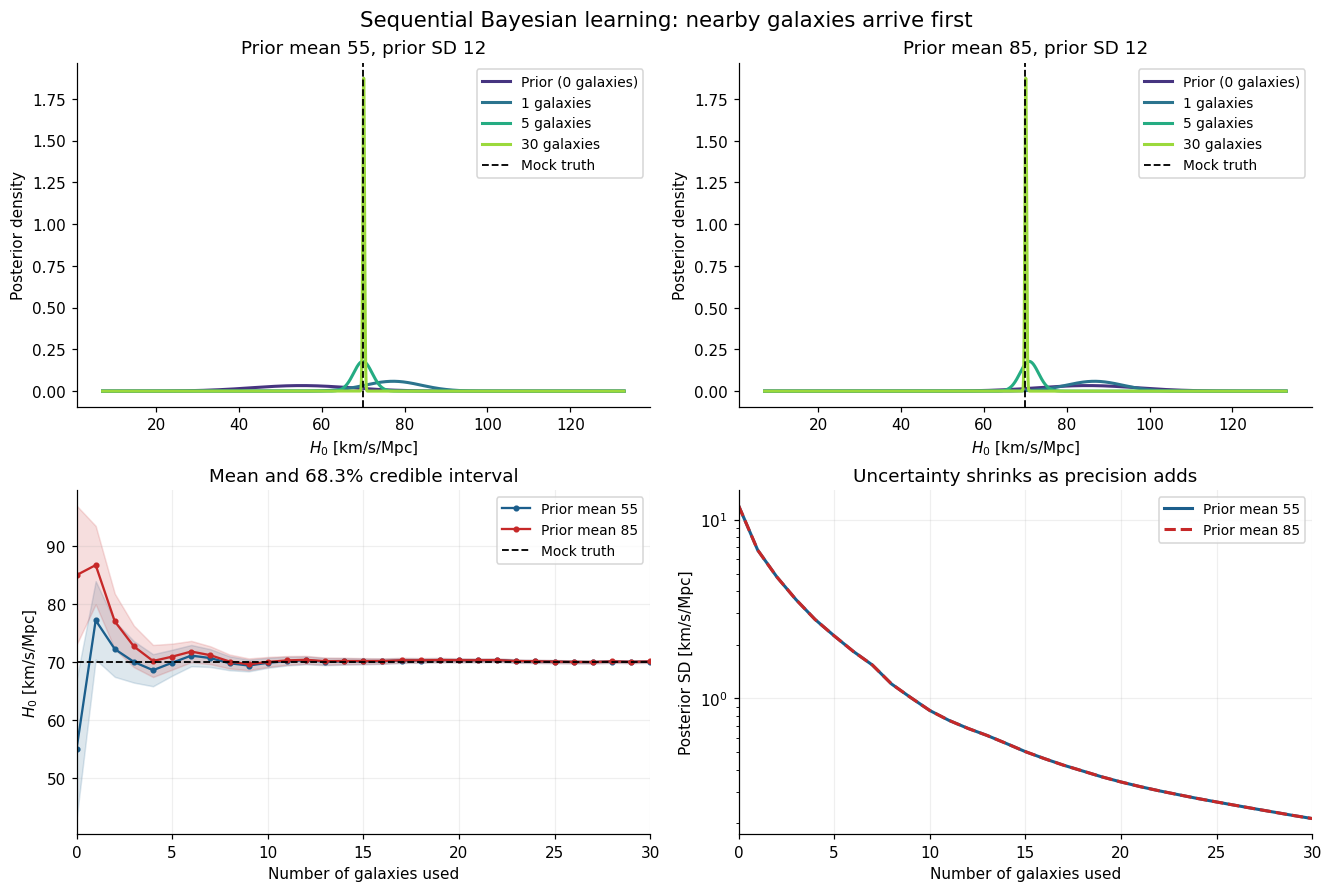

In [3]:
# Plot the Gaussian distributions and the complete update histories.
fig, axs = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
prior_colors = ('#1b5e8c', '#c62828')
stages = sorted(set([0, min(1, n_galaxies), min(5, n_galaxies), n_galaxies]))
stage_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(stages)))

# Include both priors and every posterior's +/- 4 SD range.
h_min = min(np.min(means - 4 * stds) for means, stds in posterior_history.values())
h_max = max(np.max(means + 4 * stds) for means, stds in posterior_history.values())
h_values = np.linspace(h_min, h_max, 6000)

for ax, mu0 in zip(axs[0], PRIOR_MEANS):
    means, stds = posterior_history[mu0]
    for k, color in zip(stages, stage_colors):
        # Normalized Gaussian density; its area over H0 is one.
        density = np.exp(-0.5 * ((h_values - means[k]) / stds[k])**2)
        density /= np.sqrt(2 * np.pi) * stds[k]
        label = 'Prior (0 galaxies)' if k == 0 else f'{k} galaxies'
        ax.plot(h_values, density, color=color, lw=2, label=label)
    ax.axvline(H0_TRUE, color='black', ls='--', lw=1.2, label='Mock truth')
    ax.set(title=f'Prior mean {mu0:.0f}, prior SD {PRIOR_SD:.0f}',
           xlabel=r'$H_0$ [km/s/Mpc]', ylabel='Posterior density')
    ax.legend(fontsize=9)

steps = np.arange(n_galaxies + 1)
for mu0, color in zip(PRIOR_MEANS, prior_colors):
    means, stds = posterior_history[mu0]
    label = f'Prior mean {mu0:.0f}'
    axs[1, 0].plot(steps, means, 'o-', ms=3, color=color, label=label)
    axs[1, 0].fill_between(steps, means - stds, means + stds,
                           color=color, alpha=0.15)
    # Different line styles reveal the coincident uncertainty histories.
    style = '-' if mu0 == PRIOR_MEANS[0] else '--'
    axs[1, 1].plot(steps, stds, ls=style, color=color, lw=2, label=label)

axs[1, 0].axhline(H0_TRUE, color='black', ls='--', lw=1.2, label='Mock truth')
axs[1, 0].set(title='Mean and 68.3% credible interval',
              xlabel='Number of galaxies used', ylabel=r'$H_0$ [km/s/Mpc]')
axs[1, 1].set(title='Uncertainty shrinks as precision adds',
              xlabel='Number of galaxies used',
              ylabel=r'Posterior SD [km/s/Mpc]', yscale='log')
for ax in axs[1]:
    ax.set_xlim(0, n_galaxies)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)
fig.suptitle('Sequential Bayesian learning: nearby galaxies arrive first', fontsize=14)
plt.show()

## 2. χ² and probability regions (one parameter)

Keep the model of section 1 ($a = 0$, only $H_0$ free) and look at the likelihood of all 30 galaxies. Taking $-2\ln$ of the Gaussian likelihood gives the **χ² ("chi-squared")**, the sum of squared, error-weighted residuals:

$$\chi^2(H_0) = -2\ln L + \text{const} = \sum_{i=1}^{N}\frac{(v_i - H_0 d_i)^2}{\sigma^2}, \qquad L \propto e^{-\chi^2/2}.$$

The model is linear in $H_0$, so $\chi^2$ is exactly a parabola. Completing the square:

$$\chi^2(H_0) = \chi^2_{\min} + \frac{(H_0-\hat H_0)^2}{\sigma_H^2},
\qquad \hat H_0 = \frac{\sum_i d_i v_i}{\sum_i d_i^2},
\qquad \sigma_H^2 = \frac{\sigma^2}{\sum_i d_i^2}.$$

So $L \propto \exp[-(H_0-\hat H_0)^2/2\sigma_H^2]$ is a Gaussian in $H_0$ with mean $\hat H_0$ and standard deviation $\sigma_H$. With $\Delta\chi^2 = \chi^2 - \chi^2_{\min}$:

| region | $\Delta\chi^2$ | interval | probability |
|---|---|---|---|
| 1σ | 1 | $\hat H_0 \pm \sigma_H$ | 68.3 % |
| 2σ | 4 | $\hat H_0 \pm 2\sigma_H$ | 95.4 % |

**Link to section 1.** The posterior there had precision $1/s^2 = 1/s_0^2 + \sum_i d_i^2/\sigma^2$. The second term is $1/\sigma_H^2$: the data part is exactly this χ². With 30 galaxies $\sigma_H \approx 0.2$ km/s/Mpc against a prior width $s_0 = 12$, so the prior is negligible and both observers end up on the χ² curve.

Delta chi2 <= 1: H0 in [69.88, 70.30]  (formula: 70.09 -/+ 1*0.21)  -> 68.3 %
Delta chi2 <= 4: H0 in [69.67, 70.52]  (formula: 70.09 -/+ 2*0.21)  -> 95.4 %


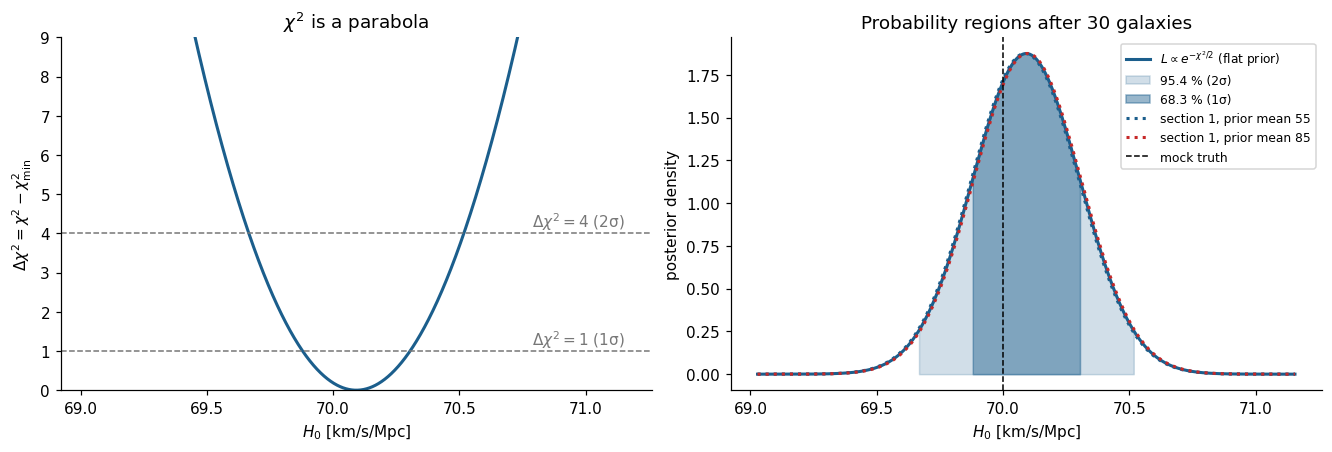

In [4]:
# chi^2(H0) for the 30 galaxies, offset a fixed to 0 (as in section 1)
H_hat = np.sum(d * v) / np.sum(d**2)          # minimum of the parabola
sig_H1 = SIG / np.sqrt(np.sum(d**2))           # its width
H1 = np.linspace(H_hat - 5 * sig_H1, H_hat + 5 * sig_H1, 2001)
chi2_1d = np.array([np.sum((v - H * d)**2) for H in H1]) / SIG**2
dchi2 = chi2_1d - chi2_1d.min()

# the Delta chi^2 = 1 and 4 crossings, read off the curve (no formula used)
for k, (dc, prob) in enumerate([(1, 68.3), (4, 95.4)], start=1):
    inside = H1[dchi2 <= dc]
    print(f'Delta chi2 <= {dc}: H0 in [{inside[0]:.2f}, {inside[-1]:.2f}]  '
          f'(formula: {H_hat:.2f} -/+ {k}*{sig_H1:.2f})  -> {prob} %')

like = np.exp(-0.5 * dchi2)
like /= trapezoid(like, H1)                     # normalise: flat-prior posterior

fig, axs = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax = axs[0]
ax.plot(H1, dchi2, color=C_POST, lw=2)
for dc, lab in [(1, r'$\Delta\chi^2=1$ (1σ)'), (4, r'$\Delta\chi^2=4$ (2σ)')]:
    ax.axhline(dc, color=C_GREY, ls='--', lw=1)
    ax.text(H1[-1], dc + 0.15, lab, ha='right', color=C_GREY)
ax.set(xlabel=r'$H_0$ [km/s/Mpc]', ylabel=r'$\Delta\chi^2=\chi^2-\chi^2_{\min}$',
       ylim=(0, 9), title=r'$\chi^2$ is a parabola')

ax = axs[1]
ax.plot(H1, like, color=C_POST, lw=2, label=r'$L\propto e^{-\chi^2/2}$ (flat prior)')
ax.fill_between(H1, like, where=dchi2 <= 4, color=C_POST, alpha=0.2, label='95.4 % (2σ)')
ax.fill_between(H1, like, where=dchi2 <= 1, color=C_POST, alpha=0.45, label='68.3 % (1σ)')
for mu0, c in zip(PRIOR_MEANS, (C_POST, C_LIK)):
    m30, s30 = posterior_history[mu0][0][-1], posterior_history[mu0][1][-1]
    ax.plot(H1, np.exp(-0.5 * ((H1 - m30) / s30)**2) / (np.sqrt(2 * np.pi) * s30),
            ls=':', color=c, lw=2, label=f'section 1, prior mean {mu0:.0f}')
ax.axvline(H0_TRUE, color='k', ls='--', lw=1, label='mock truth')
ax.set(xlabel=r'$H_0$ [km/s/Mpc]', ylabel='posterior density',
       title='Probability regions after 30 galaxies')
ax.legend(fontsize=8)
plt.show()

## 3. Fisher matrix

The **Fisher matrix** is the expected curvature of $-\ln L$ at the peak (the Hessian, averaged over data realisations). For Gaussian errors and a model $t_i(\boldsymbol\theta)$ it needs only the derivatives of the model and the errors, **no data**:

$$F_{jk} = \Big\langle -\frac{\partial^2 \ln L}{\partial\theta_j\,\partial\theta_k}\Big\rangle
= \sum_i \frac{1}{\sigma^2}\,\frac{\partial t_i}{\partial\theta_j}\,\frac{\partial t_i}{\partial\theta_k},
\qquad \sigma(\theta_j) \ge \sqrt{(F^{-1})_{jj}} .$$

### One parameter: the Gaussian of section 2

With $t_i = H_0 d_i$ we have $\partial t_i/\partial H_0 = d_i$, so

$$F = \frac{\sum_i d_i^2}{\sigma^2} = \frac12\,\frac{\partial^2\chi^2}{\partial H_0^2},
\qquad \sigma_H = \frac{1}{\sqrt F}.$$

This is the same $\sigma_H$ as in section 2: for a linear model with Gaussian noise the Fisher matrix is **exact**, because $\ln L$ is exactly quadratic. A Gaussian prior adds its precision, $F_{\rm tot} = F + 1/s_0^2$, which is exactly the update rule of section 1.

In [5]:
F_H = np.sum(d**2) / SIG**2
h = 0.01                                   # numerical second derivative of chi^2
chi2_of = lambda H: np.sum((v - H * d)**2) / SIG**2
curv = (chi2_of(H_hat + h) - 2 * chi2_of(H_hat) + chi2_of(H_hat - h)) / h**2
print(f'Fisher: F = {F_H:.2f}, sigma_H = 1/sqrt(F) = {1/np.sqrt(F_H):.3f}')
print(f'(1/2) d2chi2/dH0^2 = {curv / 2:.2f}  (numerical, same as F)')
print(f'section 2 width sigma_H = {sig_H1:.3f}')
s30 = posterior_history[PRIOR_MEANS[0]][1][-1]
print(f'Fisher + prior: 1/sqrt(F + 1/s0^2) = {1/np.sqrt(F_H + 1/PRIOR_SD**2):.4f}'
      f'  vs section 1 after 30 galaxies: {s30:.4f}')

Fisher: F = 22.09, sigma_H = 1/sqrt(F) = 0.213
(1/2) d2chi2/dH0^2 = 22.09  (numerical, same as F)
section 2 width sigma_H = 0.213
Fisher + prior: 1/sqrt(F + 1/s0^2) = 0.2127  vs section 1 after 30 galaxies: 0.2127


### Two parameters: add the offset $a$

Now free the offset: $t_i = a + H_0 d_i$, parameters $\boldsymbol\theta = (a, H_0)$, with $\partial t_i/\partial a = 1$ and $\partial t_i/\partial H_0 = d_i$:

$$F = \frac{1}{\sigma^2}\begin{pmatrix} N & \sum_i d_i \\ \sum_i d_i & \sum_i d_i^2 \end{pmatrix} = \frac{X^T X}{\sigma^2},
\qquad X = \big(\mathbf 1,\ \mathbf d\big).$$

- **Marginal** error $\sqrt{(F^{-1})_{jj}}$: the other parameter is free (integrated out). This is the one to quote.
- **Conditional** error $1/\sqrt{F_{jj}}$: the other parameter is known exactly. Always smaller or equal.
- The off-diagonal $\sum_i d_i > 0$ makes $a$ and $H_0$ anti-correlated: a larger offset can be compensated by a smaller slope. This correlation is why the marginal error is larger than the conditional one.

In 2D the regions are **contours** (lines of constant posterior). The 68.3 % region is $\Delta\chi^2 \le 2.30$ and the 95.4 % region $\Delta\chi^2 \le 6.17$, not 1 and 4: the χ² distribution with 2 degrees of freedom. Below, the shaded contours are the exact grid posterior with flat priors, the red ellipses the Fisher prediction.

Fisher: H0 = 69.85 +- 0.50, a = 69 +- 128
Conditional sigma_H (a known): 0.21; marginal: 0.50
Correlation(a, H0) = -0.903


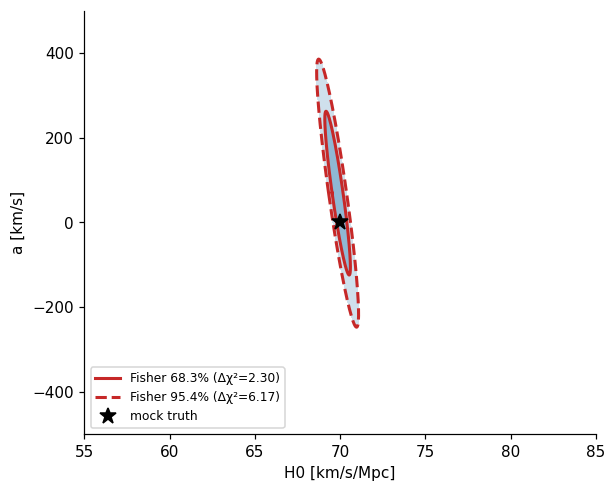

In [6]:
# exact 2D posterior on a grid, flat priors (used again in section 5)
H_grid = np.linspace(55, 85, 601)
A_grid = np.linspace(-500, 500, 601)
HH, AA = np.meshgrid(H_grid, A_grid)            # shape (len(A_grid), len(H_grid))
chi2_2d = np.sum((v[None, None, :] - AA[..., None] - HH[..., None] * d) ** 2, axis=-1) / SIG**2
post = np.exp(-0.5 * (chi2_2d - chi2_2d.min()))
post /= post.sum()

def hpd_levels(p, probs=(0.954, 0.683)):
    # posterior values whose super-level sets hold the given probabilities (ascending)
    flat = np.sort(p.ravel())[::-1]
    cum = np.cumsum(flat)
    return [flat[np.searchsorted(cum, q)] for q in probs]

X = np.column_stack([np.ones(N), d])   # order (a, H0)
F = X.T @ X / SIG**2
cov = np.linalg.inv(F)
sig_a, sig_H = np.sqrt(np.diag(cov))
a_fis, H_fis = np.linalg.solve(F, X.T @ v / SIG**2)
print(f'Fisher: H0 = {H_fis:.2f} +- {sig_H:.2f}, a = {a_fis:.0f} +- {sig_a:.0f}')
print(f'Conditional sigma_H (a known): {1/np.sqrt(F[1, 1]):.2f}; marginal: {sig_H:.2f}')
print(f'Correlation(a, H0) = {cov[0, 1] / (sig_a * sig_H):.3f}')


t = np.linspace(0, 2 * np.pi, 200)
w_, V = np.linalg.eigh(cov)
fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(HH, AA, post, levels=[*hpd_levels(post), post.max() * 1.01], colors=['#cfe0ec', '#8fb8d4'])
for p, ls, lab in [(0.683, '-', 'Fisher 68.3% (Δχ²=2.30)'), (0.954, '--', 'Fisher 95.4% (Δχ²=6.17)')]:
    ell = V @ np.diag(np.sqrt(w_ * chi2dist.ppf(p, 2))) @ np.vstack([np.cos(t), np.sin(t)])
    ax.plot(H_fis + ell[1], a_fis + ell[0], color=C_LIK, lw=2, ls=ls, label=lab)
ax.plot(H0_TRUE, A_TRUE, '*', color='k', ms=11, label='mock truth')
ax.set_xlabel('H0 [km/s/Mpc]'); ax.set_ylabel('a [km/s]'); ax.legend(loc='lower left', fontsize=8); plt.show()

## 4. Metropolis-Hastings from scratch

### Why not always use the grid?

In section 3 we computed the posterior **on a grid**: evaluate $p(\boldsymbol\theta\mid D)\propto L(\boldsymbol\theta)\,\pi(\boldsymbol\theta)$ at every point of a $601\times601$ mesh in $(H_0, a)$, normalise by the sum, and read off everything. That is exact (up to the grid spacing) and is our reference. But it costs $n^D$ likelihood calls for $n$ points per axis and $D$ parameters:

| $D$ | grid calls ($n=601$) |
|---|---|
| 2 (this toy) | $3.6\times10^{5}$ |
| 6 ($\Lambda$CDM) | $4.7\times10^{16}$ |
| 20 (with nuisance parameters) | hopeless |

and most of those points sit where the posterior is essentially zero.

### What MCMC does instead

A Markov chain Monte Carlo produces **samples** $\boldsymbol\theta_1,\dots,\boldsymbol\theta_M$ whose density follows the posterior. It spends its likelihood calls where the probability is. Metropolis-Hastings:

1. at $\boldsymbol\theta_i$, propose $\boldsymbol\theta_c = \boldsymbol\theta_i + \text{step}\times\mathcal N(0,1)$;
2. accept with probability $\min\!\big[1,\ p(\boldsymbol\theta_c\mid D)/p(\boldsymbol\theta_i\mid D)\big]$, otherwise **repeat** $\boldsymbol\theta_i$.

Only the ratio enters, so the normalisation (the evidence) is never needed. Everything the grid gave us becomes an average over samples:

$$\text{grid: } \langle f\rangle = \sum_{\text{cells}} f(\boldsymbol\theta)\,p(\boldsymbol\theta\mid D)\,\Delta\boldsymbol\theta
\qquad\longleftrightarrow\qquad
\text{MCMC: } \langle f\rangle \approx \frac1M\sum_{j=1}^{M} f(\boldsymbol\theta_j).$$

Below: four chains from dispersed starts, steps scaled by the Fisher errors of section 3, 8000 steps each, the first 1000 discarded as **burn-in** (the walk from the start towards the posterior). Checks: acceptance rate (20 to 30 % is typical), Gelman-Rubin $\hat R$ (between-chain vs within-chain variance, should be close to 1), and the autocorrelation time $\tau$ (consecutive samples are correlated; roughly $M/\tau$ of them are independent).


acceptance 22.2%
Rhat a = 1.0028, Rhat H0 = 1.0028
tau (H0, chain 0) = 15.6 steps -> about 447 independent samples per chain
likelihood calls: MCMC 32000, grid 361201


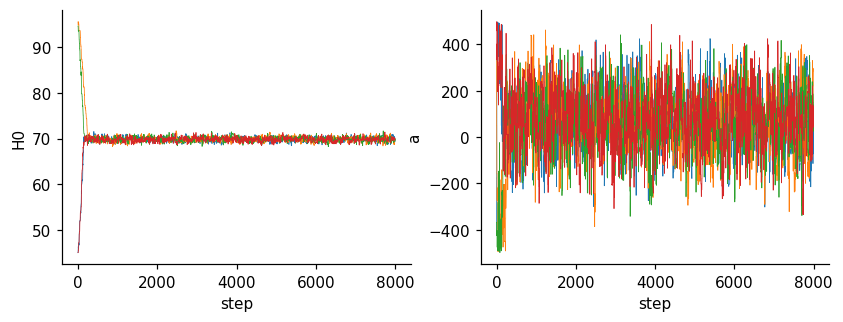

In [7]:
def logpost(th):
    a, H = th
    if not (40 <= H <= 100 and -500 <= a <= 500):
        return -np.inf
    return -0.5 * np.sum(((v - (a + H * d)) / SIG) ** 2)

def mh(start, step, n, seed):
    g = np.random.default_rng(seed)
    th = np.array(start, float)
    lp = logpost(th)
    chain = np.empty((n, 2))
    acc = 0
    for i in range(n):
        prop = th + g.normal(0, 1, 2) * step
        lpp = logpost(prop)
        if np.log(g.uniform()) < lpp - lp:
            th, lp = prop, lpp
            acc += 1
        chain[i] = th
    return chain, acc / n

def rhat(ch):
    m_, n_ = ch.shape
    W = ch.var(axis=1, ddof=1).mean()
    B = n_ * ch.mean(axis=1).var(ddof=1)
    return np.sqrt(((n_ - 1) / n_ * W + B / n_) / W)

def acf_tau(x, maxlag=300):
    x = x - x.mean()
    f = np.fft.fft(x, 2 * len(x))
    ac = np.fft.ifft(f * np.conj(f)).real[:len(x)]
    ac /= ac[0]
    return 1 + 2 * np.sum(ac[1:maxlag])

STEP = 2.38 / np.sqrt(2) * 0.8 * np.array([sig_a, sig_H])   # (a, H0)
STARTS = [(-400, 45), (400, 95), (-400, 95), (400, 45)]
N_STEPS, BURN = 8000, 1000
runs = [mh(s, STEP, N_STEPS, seed=k) for k, s in enumerate(STARTS)]
chains = np.array([c[BURN:] for c, _ in runs])   # (chain, step, parameter)
print(f'acceptance {np.mean([a for _, a in runs]):.1%}')
print(f'Rhat a = {rhat(chains[:, :, 0]):.4f}, Rhat H0 = {rhat(chains[:, :, 1]):.4f}')
tau = acf_tau(chains[0, :, 1])
print(f'tau (H0, chain 0) = {tau:.1f} steps -> about {chains[0].shape[0] / tau:.0f} independent samples per chain')
print(f'likelihood calls: MCMC {len(runs) * N_STEPS}, grid {HH.size}')

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for k in range(len(runs)):
    axs[0].plot(runs[k][0][:, 1], lw=0.5)
    axs[1].plot(runs[k][0][:, 0], lw=0.5)
axs[0].set_xlabel('step'); axs[0].set_ylabel('H0'); axs[1].set_xlabel('step'); axs[1].set_ylabel('a')
plt.show()

## 5. Grid, Fisher and MCMC compared

Three routes to the same **marginal** posteriors (the offset $a$ integrated out):

- **Grid:** marginalising is summing the grid over the other axis, $p(H_0\mid D) = \sum_a p(H_0, a\mid D)\,\Delta a$.
- **MCMC:** marginalising is free: keep the $H_0$ column of the samples and ignore $a$. The histogram is the marginal.
- **Fisher:** a Gaussian with mean at the best fit and width $\sqrt{(F^{-1})_{HH}}$.

For this linear model with Gaussian noise and wide flat priors, all three must agree; differences in the MCMC column are Monte Carlo noise. When they disagree in a real problem, the grid (if affordable) is right, the Fisher matrix is an approximation, and the MCMC may not have converged.


grid   H0 = 69.85 +- 0.49,  a = 69 +- 127
Fisher H0 = 69.85 +- 0.50,  a = 69 +- 128
MCMC   H0 = 69.85 +- 0.48,  a = 71 +- 124


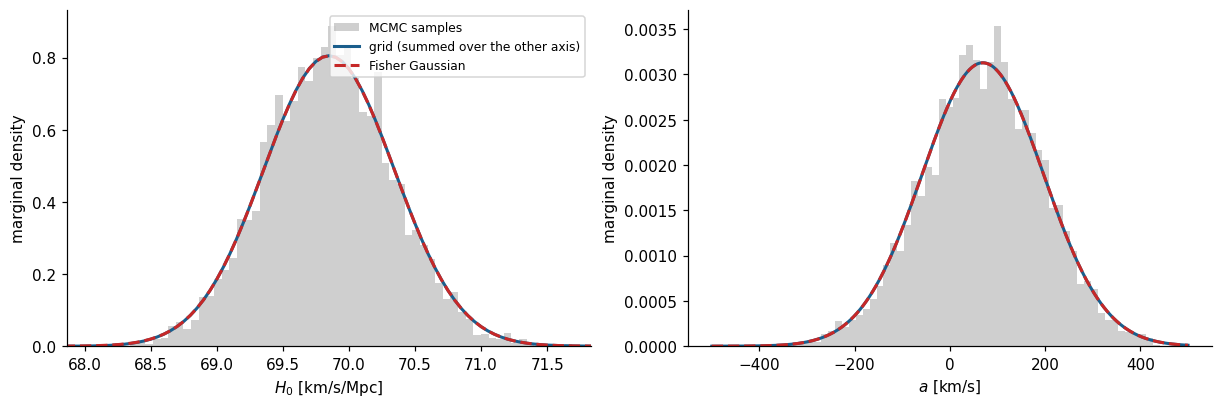

In [8]:
samples = chains.reshape(-1, 2)
H_marg = post.sum(axis=0)
A_marg = post.sum(axis=1)
H_m = np.sum(H_grid * H_marg)
H_s = np.sqrt(np.sum((H_grid - H_m) ** 2 * H_marg))
A_m = np.sum(A_grid * A_marg)
A_s = np.sqrt(np.sum((A_grid - A_m) ** 2 * A_marg))
print(f'grid   H0 = {H_m:.2f} +- {H_s:.2f},  a = {A_m:.0f} +- {A_s:.0f}')
print(f'Fisher H0 = {H_fis:.2f} +- {sig_H:.2f},  a = {a_fis:.0f} +- {sig_a:.0f}')
print(f'MCMC   H0 = {samples[:, 1].mean():.2f} +- {samples[:, 1].std():.2f},  a = {samples[:, 0].mean():.0f} +- {samples[:, 0].std():.0f}')
from scipy.stats import norm
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for ax, grid, marg, col, mu_f, s_f, lab in [
        (axs[0], H_grid, H_marg, 1, H_fis, sig_H, r'$H_0$ [km/s/Mpc]'),
        (axs[1], A_grid, A_marg, 0, a_fis, sig_a, r'$a$ [km/s]')]:
    ax.hist(samples[:, col], bins=60, density=True, color=C_GREY, alpha=0.35, label='MCMC samples')
    ax.plot(grid, marg / np.diff(grid)[0], color=C_POST, lw=2, label='grid (summed over the other axis)')
    ax.plot(grid, norm.pdf(grid, mu_f, s_f), color=C_LIK, ls='--', lw=2, label='Fisher Gaussian')
    ax.set_xlabel(lab); ax.set_ylabel('marginal density')
axs[0].set_xlim(H_fis - 4 * sig_H, H_fis + 4 * sig_H)
axs[0].legend(fontsize=8)
plt.show()


## 6. Model selection: M1 (no offset) vs M2 (offset)

$Z = \langle \mathcal{L} \rangle$ averaged over the prior box. Priors: $H_0$ uniform on $[40, 100]$, $a$ uniform on $[-W/2, W/2]$ with $W = 1000$ km/s. The integrals use the sufficient statistics of the Gaussian likelihood on a grid, so no data are sorted or dropped.

A single mock catalogue is a noisy witness: $\ln B_{12}$ depends on the one noise direction that the $H_0$ slope cannot absorb, so it scatters by several nats. We therefore show the **mean $\pm 1\sigma$ over many independent catalogues** (same galaxies and noise for both truths). Expected: for $a=400$ about 79% of the offset is absorbed by $H_0$, leaving $\Delta\chi^2\approx 23$ at $N=60$, so $\ln B_{12}\approx -10 \pm 5$; for $a=0$ the Occam factor gives $\ln B_{12}\approx +1$.

truth: no offset: lnB12 at N=60 = 1.00 +- 0.82  (mean +- 1 sigma, 100 catalogues)
truth: offset 400 km/s: lnB12 at N=60 = -10.07 +- 4.70  (mean +- 1 sigma, 100 catalogues)


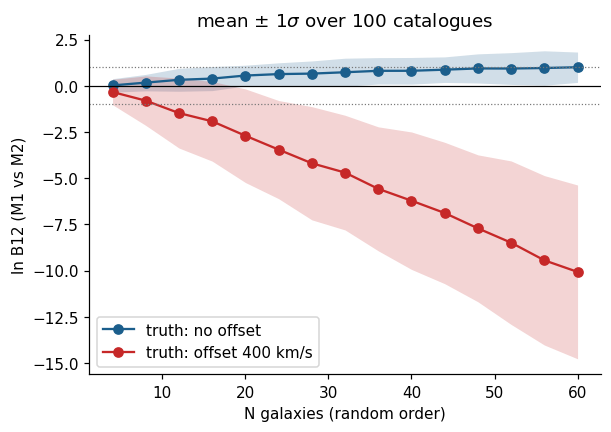

In [9]:
def lnB12(dd, vv, sig=300.0, a_width=1000.0, n_grid=401):
    n = len(dd)
    Sv, Svd, Sd, Sd2, Svv = vv.sum(), (vv * dd).sum(), dd.sum(), (dd * dd).sum(), (vv * vv).sum()
    Hg = np.linspace(40, 100, n_grid)
    ag = np.linspace(-a_width / 2, a_width / 2, n_grid)
    chi1 = (Svv - 2 * Hg * Svd + Hg ** 2 * Sd2) / sig ** 2
    lnZ1 = logsumexp(-0.5 * chi1) - np.log(n_grid)
    A, Hm = np.meshgrid(ag, Hg, indexing='ij')
    chi2 = (Svv - 2 * A * Sv - 2 * Hm * Svd + n * A ** 2 + 2 * A * Hm * Sd + Hm ** 2 * Sd2) / sig ** 2
    lnZ2 = logsumexp(-0.5 * chi2) - np.log(chi2.size)
    return lnZ1 - lnZ2

NB_GAL, N_REAL = 60, 100          # make_figs.py uses 200 catalogues (slower)
ns = np.arange(4, NB_GAL + 1, 4)
truths = {'truth: no offset': 0.0, 'truth: offset 400 km/s': 400.0}
catalogues = []                   # (d, noise) pairs, reused by the sliders below
lnB_all = {lab: np.empty((N_REAL, len(ns))) for lab in truths}
for r, ss in enumerate(np.random.SeedSequence(3).spawn(N_REAL)):
    g = np.random.default_rng(ss)
    dN = g.uniform(20, 400, NB_GAL)           # random order: the first n is a random subset
    eps = g.normal(0, SIG, NB_GAL)
    catalogues.append((dN, eps))
    for lab, a_true in truths.items():
        vN = a_true + H0_TRUE * dN + eps
        lnB_all[lab][r] = [lnB12(dN[:n], vN[:n]) for n in ns]

fig, ax = plt.subplots(figsize=(6, 4))
for lab, col in zip(truths, (C_POST, C_LIK)):
    m, s = lnB_all[lab].mean(axis=0), lnB_all[lab].std(axis=0, ddof=1)
    ax.fill_between(ns, m - s, m + s, color=col, alpha=0.2, lw=0)
    ax.plot(ns, m, 'o-', color=col, label=lab)
    print(f'{lab}: lnB12 at N=60 = {m[-1]:.2f} +- {s[-1]:.2f}  (mean +- 1 sigma, {N_REAL} catalogues)')
ax.axhline(0, color='k', lw=0.8)
for y in (1, -1):
    ax.axhline(y, color=C_GREY, ls=':', lw=0.8)
ax.set_xlabel('N galaxies (random order)'); ax.set_ylabel('ln B12 (M1 vs M2)')
ax.set_title(f'mean $\\pm$ 1$\\sigma$ over {N_REAL} catalogues'); ax.legend(); plt.show()


## 7. Interactive: step size, prior width and noise

Needs ipywidgets. Without it the cells above still run with the fixed values. The sliders change either the sampler (left) or the model (right). The model slider reports $\ln B_{12}$ as mean $\pm 1\sigma$ over 20 of the offset-400 catalogues from section 6, not a single realisation.

In [10]:
try:
    import ipywidgets as wdg
    from IPython.display import display
except ImportError:
    wdg = None
    print('ipywidgets not installed: sliders skipped (pip install ipywidgets to enable).')

if wdg is not None:
    cats = [(d_, 400.0 + H0_TRUE * d_ + e_) for d_, e_ in catalogues[:20]]   # offset-400 catalogues from section 6

    def show_mh(log10_scale, steps):
        ch, acc = mh((-400, 45), STEP * 10 ** log10_scale, int(steps), seed=7)
        fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), constrained_layout=True)
        axs[0].plot(ch[:, 1], color=C_POST, lw=0.6); axs[0].set_xlabel('step'); axs[0].set_ylabel('H0')
        axs[1].plot(ch[:, 0], color=C_LIK, lw=0.6); axs[1].set_xlabel('step'); axs[1].set_ylabel('a')
        fig.suptitle(f'step = {10 ** log10_scale:.2g} x tuned step, acceptance = {acc:.0%}')
        plt.show()

    def show_evidence(sig, width):
        vals = np.array([lnB12(d_, v_, sig, width, n_grid=201) for d_, v_ in cats])
        print(f'sigma = {sig:.0f} km/s, prior width on a = {width:.0f} km/s: '
              f'lnB12 = {vals.mean():.2f} +- {vals.std(ddof=1):.2f}  (> 0 favours M1, no offset)')

    # continuous_update=False: recompute only when the slider is released
    s_step = wdg.FloatSlider(value=0, min=-1.5, max=1.0, step=0.1, description='log10 step',
                             continuous_update=False)
    s_n = wdg.IntSlider(value=3000, min=500, max=8000, step=500, description='steps',
                        continuous_update=False)
    s_sig = wdg.FloatSlider(value=300, min=100, max=600, step=25, description='sigma',
                            continuous_update=False)
    s_w = wdg.FloatSlider(value=1000, min=200, max=2000, step=100, description='a prior width',
                          continuous_update=False)
    out1 = wdg.interactive_output(show_mh, {'log10_scale': s_step, 'steps': s_n})
    out2 = wdg.interactive_output(show_evidence, {'sig': s_sig, 'width': s_w})
    display(wdg.VBox([wdg.HBox([s_step, s_n]), out1, wdg.HBox([s_sig, s_w]), out2]))


Expected values (same seed 42 as `make_figs.py`, so they match `numbers.json` and the slides): Fisher $H_0 = 69.8 \pm 0.5$, $a = 69 \pm 128$ km/s; MCMC $H_0 = 69.8 \pm 0.5$, $a = 71 \pm 124$ km/s; $\hat R = 1.003$, acceptance about 22%; lnB12 at N = 60 (mean $\pm$ 1 sigma over catalogues) about +1.0 $\pm$ 0.8 (no offset) and -10 $\pm$ 5 (offset 400 km/s); `make_figs.py` uses 200 catalogues, this notebook 100.